# CSE-CIC-IDS2018 ile Tekrar ve 2017 Karşılaştırması

> Açıklamalar Türkçedir; tablolar, grafikler ve sonuç dosyaları uluslararası kullanım için İngilizce hazırlanmıştır (ör. *Random* = rastgele saldırgan, *Adaptive* = uyarlamalı saldırgan, *Size* = boyut, *Time* = zaman).

**Amaç.** `00_cicids2017_robustness_experiments.ipynb`'de CIC-IDS2017 üzerinde yapılan deneylerin (baseline, pertürbasyon duyarlılığı, dayanıklılık sıralaması) farklı bir veri setinde de aynı sonucu verip vermediğini görmek.

**Soru.** İki veri seti arasında modellerin başarısı ve pertürbasyona karşı dayanıklılığı açısından fark var mı? Varsa ne kadar?

**Adil karşılaştırma için sabit tutulanlar:** aynı 64 özellik, aynı temizlik adımları, aynı modeller ve hiperparametreler, aynı seedler, aynı ε seviyeleri, aynı saldırganlar ve aynı ağ kısıtları. Fonksiyonlar `00_cicids2017_robustness_experiments.ipynb`'dekilerle birebir aynıdır.

**Farklar:**
- 2018 veri setinde aynı özellikler kısaltılmış adlarla gelir (ör. `Tot Fwd Pkts`). Bunlar 2017 adlarına eşlenir.
- 2018 veri seti yaklaşık 3,5 kat büyük olduğu için her dosyadan aynı oranda rastgele örnek alınır. Böylece sınıf dağılımı korunur ve veri boyutu 2017'ye yakın olur.
- 3,9 GB'lık 20-02-2018 günü (yalnızca DDoS-LOIC-HTTP saldırısı içerir) boyutu nedeniyle dahil edilmemiştir. DDoS saldırıları HOIC ve LOIC-UDP ile temsil edilmektedir.
- Özellik önemi ve ablation (Deney D) tekrarlanmamıştır; bu notebook yalnızca dayanıklılık karşılaştırmasına odaklanır.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)
from xgboost import XGBClassifier

In [2]:
DATA_DIR = Path("../data/raw/CSE-CIC-IDS2018")
METRICS_2017 = Path("../results/metrics")             # 00_cicids2017_robustness_experiments.ipynb'nin sonuçları
GRAPHS_DIR = Path("../results/graphs/2018")
METRICS_DIR = Path("../results/metrics/2018")
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_FRAC = 0.30          # her dosyadan alınan rastgele örnek oranı
SAMPLE_SEED = 0

# 00_cicids2017_robustness_experiments.ipynb ile aynı deney ayarları
SEEDS = [42, 100, 2024]
TEST_SIZE = 0.20
EPSILONS = [0.0, 0.05, 0.10, 0.25, 0.50, 1.00]
EPS_REF = 0.50
ADAPTIVE_GRID = 4
DECISION_THRESHOLD = 0.5

MODEL_NAMES = ["Random Forest", "XGBoost", "MLP"]
METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
ATTACKERS = ["Random", "Adaptive"]
SCENARIO_GROUPS = ["Size", "Time", "Size+Time"]
DATASETS = ["CIC-IDS2017", "CSE-CIC-IDS2018"]

In [3]:
# Grafik ve tablo stili
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"

MODEL_COLORS = {"Random Forest": "#2a78d6", "XGBoost": "#eb6834", "MLP": "#1baf7a"}
SCENARIO_COLORS = {"Clean": AXIS, "Size": "#eda100", "Time": "#e87ba4", "Size+Time": "#008300"}
GROUP_COLORS = {"Size": "#eda100", "Time": "#e87ba4", "Rate": "#6250d6", "Count/Protocol": MUTED}
BLUE_SEQ = LinearSegmentedColormap.from_list(
    "blue_seq", ["#f2f7fe", "#b7d3f6", "#5598e7", "#1c5cab", "#0d366b"]
)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 10, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

TABLE_STYLES = [
    {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; "
                                     "font-size: 13px; color: #0b0b0b; padding: 4px 0 8px 0;"},
    {"selector": "th", "props": "background: #f3f2ee; color: #0b0b0b; font-weight: 600; text-align: left; "
                                "padding: 6px 12px; border-bottom: 1px solid #c3c2b7;"},
    {"selector": "td", "props": "padding: 5px 12px; border-bottom: 1px solid #ecebe6; "
                                "font-variant-numeric: tabular-nums;"},
]


def save_fig(fig, name):
    fig.savefig(GRAPHS_DIR / f"{name}.png")
    plt.show()


def fig_title(fig, title, subtitle=None):
    # Başlık ve alt başlık, eksenlerin üstüne sabit (inç cinsinden) boşlukla yerleştirilir.
    h = fig.get_figheight()
    fig.text(0.01, 1 + 0.42 / h, title, ha="left", va="bottom", fontsize=12.5, fontweight="semibold")
    if subtitle:
        fig.text(0.01, 1 + 0.14 / h, subtitle, ha="left", va="bottom", fontsize=9.5, color=INK_2)


def top_legend(fig, handles, labels=None, **kwargs):
    h = fig.get_figheight()
    labels = labels if labels is not None else [hd.get_label() for hd in handles]
    fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.995, 1 + 0.36 / h),
               ncol=kwargs.pop("ncol", len(handles)), **kwargs)


def show_table(df, title, filename=None, precision=4):
    # Tabloyu CSV olarak kaydeder ve notebook'ta biçimlendirilmiş hâlde gösterir.
    if filename:
        df.to_csv(METRICS_DIR / filename, index=False, encoding="utf-8-sig")
    styler = (df.style.set_caption(title).hide(axis="index")
              .set_table_styles(TABLE_STYLES).format(precision=precision, thousands=","))
    display(styler)


def format_pm(mean, std, digits=4):
    # Ortalama ve standart sapma tablolarını "ortalama ± std" metnine çevirir.
    out = pd.DataFrame(index=mean.index)
    for col in mean.columns:
        d = digits.get(col, 4) if isinstance(digits, dict) else digits
        out[col] = [f"{m:,.{d}f} ± {s:,.{d}f}" for m, s in zip(mean[col], std[col].fillna(0))]
    return out


DATASET_COLORS = {"CIC-IDS2017": "#2a78d6", "CSE-CIC-IDS2018": "#eb6834"}

## 1. Veri Setinin Yüklenmesi ve Özellik Eşleme

2018 dosyalarında özellik adları kısaltılmıştır. Aşağıdaki sözlük, adı farklı olan sütunları 2017'deki karşılıklarına eşler; adı aynı olanlar (ör. `Flow Duration`, `Flow IAT Mean`) olduğu gibi kalır. Yalnızca 2017'de kullanılan 64 özellik ve etiket tutulur. 2018'e özgü `Protocol` ve `Timestamp` sütunları ile `Dst Port` kullanılmaz.

Bazı 2018 dosyalarında başlık satırı veri içinde tekrar eder; bu satırlar atılır ve tüm özellikler sayıya çevrilir. Dosyalar bellek için parça parça okunur ve her parçadan `SAMPLE_FRAC` oranında rastgele örnek alınır.

In [4]:
COLUMN_MAP_2018 = {
    "Tot Fwd Pkts": "Total Fwd Packets", "Tot Bwd Pkts": "Total Backward Packets",
    "TotLen Fwd Pkts": "Total Length of Fwd Packets", "TotLen Bwd Pkts": "Total Length of Bwd Packets",
    "Fwd Pkt Len Max": "Fwd Packet Length Max", "Fwd Pkt Len Min": "Fwd Packet Length Min",
    "Fwd Pkt Len Mean": "Fwd Packet Length Mean", "Fwd Pkt Len Std": "Fwd Packet Length Std",
    "Bwd Pkt Len Max": "Bwd Packet Length Max", "Bwd Pkt Len Min": "Bwd Packet Length Min",
    "Bwd Pkt Len Mean": "Bwd Packet Length Mean", "Bwd Pkt Len Std": "Bwd Packet Length Std",
    "Flow Byts/s": "Flow Bytes/s", "Flow Pkts/s": "Flow Packets/s",
    "Fwd IAT Tot": "Fwd IAT Total", "Bwd IAT Tot": "Bwd IAT Total",
    "Fwd Header Len": "Fwd Header Length", "Bwd Header Len": "Bwd Header Length",
    "Fwd Pkts/s": "Fwd Packets/s", "Bwd Pkts/s": "Bwd Packets/s",
    "Pkt Len Min": "Min Packet Length", "Pkt Len Max": "Max Packet Length",
    "Pkt Len Mean": "Packet Length Mean", "Pkt Len Std": "Packet Length Std", "Pkt Len Var": "Packet Length Variance",
    "FIN Flag Cnt": "FIN Flag Count", "RST Flag Cnt": "RST Flag Count", "PSH Flag Cnt": "PSH Flag Count",
    "ACK Flag Cnt": "ACK Flag Count", "URG Flag Cnt": "URG Flag Count", "ECE Flag Cnt": "ECE Flag Count",
    "Pkt Size Avg": "Average Packet Size", "Fwd Seg Size Avg": "Avg Fwd Segment Size",
    "Bwd Seg Size Avg": "Avg Bwd Segment Size", "Subflow Fwd Byts": "Subflow Fwd Bytes",
    "Subflow Bwd Byts": "Subflow Bwd Bytes", "Init Fwd Win Byts": "Init_Win_bytes_forward",
    "Init Bwd Win Byts": "Init_Win_bytes_backward", "Fwd Act Data Pkts": "act_data_pkt_fwd",
    "Fwd Seg Size Min": "min_seg_size_forward",
}

# 00_cicids2017_robustness_experiments.ipynb'de temizlik sonrası kalan 64 özellik (grup sırasıyla)
FEATURES = [
    # Boyut
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
    "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
    "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std", "Packet Length Variance",
    "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size", "Subflow Fwd Bytes", "Subflow Bwd Bytes",
    # Zaman
    "Flow Duration", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Active Max", "Active Min", "Idle Mean", "Idle Std", "Idle Max", "Idle Min",
    # Hız
    "Flow Bytes/s", "Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s",
    # Sayaç/Protokol
    "Total Fwd Packets", "Total Backward Packets", "Fwd PSH Flags", "Fwd URG Flags",
    "Fwd Header Length", "Bwd Header Length", "FIN Flag Count", "RST Flag Count", "PSH Flag Count",
    "ACK Flag Count", "URG Flag Count", "ECE Flag Count", "Down/Up Ratio",
    "Init_Win_bytes_forward", "Init_Win_bytes_backward", "act_data_pkt_fwd", "min_seg_size_forward",
]
assert len(FEATURES) == 64


def read_2018_file(path):
    parts = []
    for chunk in pd.read_csv(path, chunksize=500_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk[chunk["Label"] != "Label"]                  # tekrar eden başlık satırları
        chunk = chunk.sample(frac=SAMPLE_FRAC, random_state=SAMPLE_SEED)
        chunk = chunk.rename(columns=COLUMN_MAP_2018)[FEATURES + ["Label"]]
        chunk[FEATURES] = chunk[FEATURES].apply(pd.to_numeric, errors="coerce")
        parts.append(chunk)
    return pd.concat(parts)


csv_files = sorted(DATA_DIR.glob("*.csv"))
frames = []
for path in csv_files:
    df = read_2018_file(path)
    frames.append(df)
    print(f"{path.name:<55}{len(df):>11,} satır (örneklem)")

data = pd.concat(frames, ignore_index=True)
del frames
data["Label"] = data["Label"].astype(str).str.strip()
print(f"\nToplam örneklem: {data.shape[0]:,} satır, {len(FEATURES)} özellik")

Friday-02-03-2018_TrafficForML_CICFlowMeter.csv            314,572 satır (örneklem)


Friday-16-02-2018_TrafficForML_CICFlowMeter.csv            314,572 satır (örneklem)


Friday-23-02-2018_TrafficForML_CICFlowMeter.csv            314,572 satır (örneklem)


Thursday-01-03-2018_TrafficForML_CICFlowMeter.csv           99,330 satır (örneklem)


Thursday-15-02-2018_TrafficForML_CICFlowMeter.csv          314,572 satır (örneklem)


Thursday-22-02-2018_TrafficForML_CICFlowMeter.csv          314,572 satır (örneklem)


Wednesday-14-02-2018_TrafficForML_CICFlowMeter.csv         314,572 satır (örneklem)


Wednesday-21-02-2018_TrafficForML_CICFlowMeter.csv         314,572 satır (örneklem)


Wednesday-28-02-2018_TrafficForML_CICFlowMeter.csv         183,922 satır (örneklem)



Toplam örneklem: 2,485,256 satır, 64 özellik


## 2. Veri Temizleme

`00_cicids2017_robustness_experiments.ipynb` ile aynı adımlar uygulanır: sonsuz/eksik değerler, fiziksel olarak geçersiz (negatif) değerler, etiket çakışmaları ve tekrar eden satırlar. Sütun silme adımları yoktur, çünkü özellik listesi 2017'den sabit alınmıştır.

In [5]:
cleaning_log = []


def log_step(step, rows_before, note):
    cleaning_log.append({"Step": step, "Rows removed": rows_before - len(data),
                         "Rows remaining": len(data), "Note": note})


r = len(data)
n_inf = int(np.isinf(data[FEATURES]).sum().sum())
data[FEATURES] = data[FEATURES].replace([np.inf, -np.inf], np.nan)
data = data.dropna()
log_step("Infinite / missing values", r, f"{n_inf:,} infinite values converted to missing")

r = len(data)
nonneg_cols = [c for c in FEATURES if not c.startswith("Init_Win_bytes")]
data = data[(data[nonneg_cols] >= 0).all(axis=1)]
log_step("Negative values", r, "Duration, size and rate cannot be negative")

data["Target"] = (data["Label"] != "Benign").astype("int8")
r = len(data)
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
n_targets = data["Target"].groupby(row_hash.values).transform("nunique")
data = data[(n_targets == 1).values]
log_step("Label conflicts", r, "Identical features labelled both benign and attack")

r = len(data)
row_hash = pd.util.hash_pandas_object(data[FEATURES], index=False)
data = data[~row_hash.duplicated().values].reset_index(drop=True)
log_step("Duplicate rows", r, "Rows with identical features deduplicated")

X = data[FEATURES].astype("float64")
y = data["Target"]
labels = data["Label"]
INT_COLS = [c for c in FEATURES if np.array_equal(X[c].to_numpy(), np.round(X[c].to_numpy()))]
del data

show_table(pd.DataFrame(cleaning_log), "Table 1 — CSE-CIC-IDS2018 data cleaning steps", "data_cleaning.csv")

label_counts = labels.value_counts()
show_table(pd.DataFrame({"Class": label_counts.index, "Records": label_counts.values,
                         "Share (%)": (label_counts.values / len(labels) * 100).round(4)}),
           "Table 2 — Label distribution (after cleaning)", "class_distribution.csv")
print(f"Son veri: {len(X):,} satır · saldırı oranı %{y.mean() * 100:.2f}")

Step,Rows removed,Rows remaining,Note
Infinite / missing values,"10,869","2,474,387","14,861 infinite values converted to missing"
Negative values,6,"2,474,381","Duration, size and rate cannot be negative"
Label conflicts,"68,524","2,405,857",Identical features labelled both benign and attack
Duplicate rows,"671,638","1,734,219",Rows with identical features deduplicated


Class,Records,Share (%)
Benign,"1,471,804",84.8684
DDOS attack-HOIC,"77,515",4.4697
DoS attacks-Hulk,"65,687",3.7877
Bot,"43,711",2.5205
Infilteration,"30,700",1.7702
SSH-Bruteforce,"28,364",1.6355
DoS attacks-GoldenEye,"12,543",0.7233
DoS attacks-Slowloris,"2,989",0.1724
DDOS attack-LOIC-UDP,536,0.0309
Brute Force -Web,180,0.0104


Son veri: 1,734,219 satır · saldırı oranı %15.13


## 3. Modeller, Özellik Grupları ve Pertürbasyon

Aşağıdaki üç hücre `00_cicids2017_robustness_experiments.ipynb`'deki fonksiyonların birebir kopyasıdır: model tanımları ve metrikler, özellik grupları, ağ kısıtlarını koruyan pertürbasyon ve iki saldırgan türü.

In [6]:
def make_model(name, seed):
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed)
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=200, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
            tree_method="hist", eval_metric="logloss", importance_type="gain", n_jobs=-1, random_state=seed,
        )
    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(64, 32), batch_size=1024, learning_rate_init=1e-3, max_iter=100,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=5, random_state=seed,
        )
    raise ValueError(name)


def split_data(seed):
    return train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)


def compute_metrics(y_true, proba):
    y_true = np.asarray(y_true)
    y_pred = (proba >= DECISION_THRESHOLD).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

In [7]:
def present(columns):
    return [c for c in columns if c in FEATURES]


SIZE_FEATURES = present([
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
    "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
    "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std", "Packet Length Variance",
    "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size", "Subflow Fwd Bytes", "Subflow Bwd Bytes",
])
TIME_FEATURES = present([
    "Flow Duration",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
    "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min",
    "Active Mean", "Active Std", "Active Max", "Active Min",
    "Idle Mean", "Idle Std", "Idle Max", "Idle Min",
])
RATE_FEATURES = present(["Flow Bytes/s", "Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"])
COUNT_PROTOCOL_FEATURES = [c for c in FEATURES if c not in SIZE_FEATURES + TIME_FEATURES + RATE_FEATURES]

FEATURE_GROUPS = {
    "Size": SIZE_FEATURES, "Time": TIME_FEATURES,
    "Rate": RATE_FEATURES, "Count/Protocol": COUNT_PROTOCOL_FEATURES,
}
FEATURE_TO_GROUP = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}

# Saldırganın değiştirebildiği / dolaylı olarak değişen özellikler
FWD_SIZE_SCALED = present([
    "Total Length of Fwd Packets", "Fwd Packet Length Max", "Fwd Packet Length Min",
    "Fwd Packet Length Mean", "Fwd Packet Length Std", "Avg Fwd Segment Size", "Subflow Fwd Bytes",
])
BIDIR_SIZE_DERIVED = present(["Max Packet Length", "Packet Length Mean", "Average Packet Size"])
MODIFIED_FEATURES = FWD_SIZE_SCALED + BIDIR_SIZE_DERIVED + TIME_FEATURES + RATE_FEATURES
FIXED_SIZE_FEATURES = [c for c in SIZE_FEATURES if c not in FWD_SIZE_SCALED + BIDIR_SIZE_DERIVED]

In [8]:
def max_allowed_factor(X_raw, columns, upper):
    # Her akış için, verilen sütunların hiçbiri eğitim maksimumunu aşmayacak şekilde en büyük katsayı.
    if not columns:
        return np.full(len(X_raw), np.inf)
    values = X_raw[columns].to_numpy()
    limits = upper[columns].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(values > 0, limits / values, np.inf)
    return np.maximum(ratio.min(axis=1), 1.0)


def apply_perturbation(X_raw, size_factor, time_factor, bounds):
    # Saldırı akışlarına (ham birimlerde) ağ kısıtlarını koruyan pertürbasyon uygular.
    lower, upper = bounds
    X_adv = X_raw.copy()
    n = len(X_adv)
    s = np.broadcast_to(np.asarray(size_factor, dtype=float), (n,)).copy()
    t = np.broadcast_to(np.asarray(time_factor, dtype=float), (n,)).copy()

    # Geçerli aralık: katsayılar eğitim maksimumunu aşmayacak şekilde sınırlandırılır
    s = np.minimum(s, max_allowed_factor(X_adv, FWD_SIZE_SCALED, upper))
    t = np.minimum(t, max_allowed_factor(X_adv, TIME_FEATURES, upper))

    # Boyut: ileri yöndeki her pakete orantılı padding
    fwd_bytes_old = X_adv["Total Length of Fwd Packets"].to_numpy().copy()
    X_adv[FWD_SIZE_SCALED] = X_adv[FWD_SIZE_SCALED].to_numpy() * s[:, None]
    added_bytes = X_adv["Total Length of Fwd Packets"].to_numpy() - fwd_bytes_old

    # Çift yön türetilmiş boyutlar: eklenen bayt tüm paketlere bölünür, en büyük paket güncellenir
    n_packets = (X_adv["Total Fwd Packets"] + X_adv["Total Backward Packets"]).to_numpy()
    for col in present(["Packet Length Mean", "Average Packet Size"]):
        X_adv[col] = X_adv[col].to_numpy() + added_bytes / np.maximum(n_packets, 1)
    if "Max Packet Length" in X_adv:
        X_adv["Max Packet Length"] = np.maximum(X_adv["Max Packet Length"], X_adv["Fwd Packet Length Max"])

    # Zaman: akış t katı yavaşlatılır
    T = X_adv[TIME_FEATURES].to_numpy()
    X_adv[TIME_FEATURES] = np.where(T > 0, T * t[:, None], T)

    # Hız: yeni bayt miktarı ve yeni süreden yeniden hesaplanır
    total_bytes_old = fwd_bytes_old + X_adv["Total Length of Bwd Packets"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        byte_ratio = np.where(total_bytes_old > 0, (total_bytes_old + added_bytes) / total_bytes_old, 1.0)
    if "Flow Bytes/s" in X_adv:
        X_adv["Flow Bytes/s"] = X_adv["Flow Bytes/s"].to_numpy() * byte_ratio / t
    for col in present(["Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"]):
        X_adv[col] = X_adv[col].to_numpy() / t

    # Tam sayı özellikler yuvarlanır, değişen özellikler geçerli aralıkta tutulur
    int_modified = [c for c in MODIFIED_FEATURES if c in INT_COLS]
    X_adv[int_modified] = np.round(X_adv[int_modified].to_numpy())
    X_adv[MODIFIED_FEATURES] = X_adv[MODIFIED_FEATURES].clip(
        lower=lower[MODIFIED_FEATURES], upper=upper[MODIFIED_FEATURES], axis=1
    )
    return X_adv


def attack_probabilities(attacker, group, eps, X_att, bounds, score_fn, rng):
    # Seçilen saldırgan ve özellik grubu için pertürbe edilmiş saldırı akışlarının model skorlarını döndürür.
    n = len(X_att)
    use_size, use_time = "Size" in group, "Time" in group

    if attacker == "Random":
        s = 1 + rng.uniform(0, eps, n) if use_size else np.ones(n)
        t = 1 + rng.uniform(0, eps, n) if use_time else np.ones(n)
        return score_fn(apply_perturbation(X_att, s, t, bounds))

    # Uyarlamalı kara kutu saldırgan: aday katsayıları sorgular, en düşük skoru veren seçeneği tutar
    levels = 1 + np.linspace(0, eps, ADAPTIVE_GRID)
    best_p = np.full(n, np.inf)
    for s in (levels if use_size else [1.0]):
        for t in (levels if use_time else [1.0]):
            best_p = np.minimum(best_p, score_fn(apply_perturbation(X_att, s, t, bounds)))
    return best_p

## 4. Deneyler (A ve B)

`00_cicids2017_robustness_experiments.ipynb`'deki ana döngünün aynısıdır: her seed için veri bölünür, üç model eğitilir, temiz test verisinde (Deney A) ve her `(saldırgan, grup, ε)` kombinasyonunda pertürbe edilmiş saldırı akışlarıyla (Deney B) değerlendirilir.

In [9]:
baseline_rows, perturbation_rows = [], []
start = time.time()

for seed in SEEDS:
    X_tr, X_te, y_tr, y_te = split_data(seed)
    scaler = StandardScaler().fit(X_tr)
    Xs_tr = scaler.transform(X_tr).astype(np.float32)
    Xs_te = scaler.transform(X_te).astype(np.float32)
    bounds = (X_tr.min(), X_tr.max())

    is_attack = (y_te == 1).to_numpy()
    X_att = X_te[is_attack]
    y_eval = np.r_[np.zeros((~is_attack).sum(), dtype=np.int8), np.ones(is_attack.sum(), dtype=np.int8)]
    rng = np.random.default_rng(seed)

    for name in MODEL_NAMES:
        t0 = time.time()
        model = make_model(name, seed).fit(Xs_tr, y_tr.to_numpy())

        def score_fn(X_raw, model=model):
            return model.predict_proba(scaler.transform(X_raw).astype(np.float32))[:, 1]

        p_clean = model.predict_proba(Xs_te)[:, 1]
        baseline_rows.append({"Seed": seed, "Model": name, **compute_metrics(y_te, p_clean)})

        p_benign = p_clean[~is_attack]
        for attacker in ATTACKERS:
            for group in SCENARIO_GROUPS:
                for eps in EPSILONS:
                    if eps == 0:
                        p_att = p_clean[is_attack]
                    else:
                        p_att = attack_probabilities(attacker, group, eps, X_att, bounds, score_fn, rng)
                    perturbation_rows.append({"Seed": seed, "Model": name, "Attacker": attacker, "Group": group,
                                              "Epsilon": eps, **compute_metrics(y_eval, np.r_[p_benign, p_att])})

        print(f"seed {seed:<5} {name:<14} tamamlandı  ({time.time() - t0:,.0f} sn)")
        del model

baseline_df = pd.DataFrame(baseline_rows)
perturbation_df = pd.DataFrame(perturbation_rows)
baseline_df.to_csv(METRICS_DIR / "raw_experiment_A_per_seed.csv", index=False, encoding="utf-8-sig")
perturbation_df.to_csv(METRICS_DIR / "raw_experiment_B_per_seed.csv", index=False, encoding="utf-8-sig")
print(f"\nToplam süre: {(time.time() - start) / 60:,.1f} dk")

seed 42    Random Forest  tamamlandı  (144 sn)


seed 42    XGBoost        tamamlandı  (56 sn)


seed 42    MLP            tamamlandı  (50 sn)


seed 100   Random Forest  tamamlandı  (148 sn)


seed 100   XGBoost        tamamlandı  (55 sn)


seed 100   MLP            tamamlandı  (56 sn)


seed 2024  Random Forest  tamamlandı  (145 sn)


seed 2024  XGBoost        tamamlandı  (55 sn)


seed 2024  MLP            tamamlandı  (58 sn)

Toplam süre: 13.0 dk


## 5. 2017 ve 2018 Karşılaştırması

`00_cicids2017_robustness_experiments.ipynb`'nin kaydettiği seed bazındaki ham sonuçlar okunur ve 2018 sonuçlarıyla birleştirilir. Veri setlerinin test kümesindeki saldırı sayıları farklı olduğundan, kaçırılan saldırılar sayı olarak değil **test kümesindeki saldırılara oranı (%)** olarak karşılaştırılır.

In [10]:
base_all = pd.concat([
    pd.read_csv(METRICS_2017 / "raw_experiment_A_per_seed.csv").assign(**{"Dataset": DATASETS[0]}),
    baseline_df.assign(**{"Dataset": DATASETS[1]}),
], ignore_index=True)
pert_all = pd.concat([
    pd.read_csv(METRICS_2017 / "raw_experiment_B_per_seed.csv").assign(**{"Dataset": DATASETS[0]}),
    perturbation_df.assign(**{"Dataset": DATASETS[1]}),
], ignore_index=True)
pert_all["Missed attacks (%)"] = pert_all["FN"] / (pert_all["FN"] + pert_all["TP"]) * 100

# Tablo K1: temiz veride başarı
g = base_all.groupby(["Model", "Dataset"])[["F1", "Recall", "Precision", "PR-AUC"]]
k1 = format_pm(g.mean(), g.std()).unstack("Dataset")
k1 = k1.reindex(MODEL_NAMES)
k1.columns = [f"{metric} · {ds[-4:]}" for metric, ds in k1.columns]
show_table(k1.reset_index(), f"Table K1 — Performance on clean test data ({len(SEEDS)} seeds, mean ± std)",
           "comparison_baseline.csv")

Model,F1 · 2017,F1 · 2018,Recall · 2017,Recall · 2018,Precision · 2017,Precision · 2018,PR-AUC · 2017,PR-AUC · 2018
Random Forest,0.9971 ± 0.0002,0.9233 ± 0.0008,0.9958 ± 0.0004,0.8877 ± 0.0017,0.9984 ± 0.0000,0.9618 ± 0.0009,0.9999 ± 0.0000,0.9545 ± 0.0011
XGBoost,0.9980 ± 0.0001,0.9369 ± 0.0008,0.9977 ± 0.0003,0.8855 ± 0.0018,0.9983 ± 0.0002,0.9946 ± 0.0008,1.0000 ± 0.0000,0.9656 ± 0.0004
MLP,0.9870 ± 0.0014,0.9322 ± 0.0010,0.9844 ± 0.0009,0.8788 ± 0.0007,0.9896 ± 0.0019,0.9925 ± 0.0014,0.9988 ± 0.0002,0.9516 ± 0.0001


In [11]:
# Tablo K2: dayanıklılık (uyarlamalı saldırgan, Boyut+Zaman, ε = EPS_REF)
keys = ["Dataset", "Seed", "Model", "Attacker", "Group"]
clean = pert_all[pert_all["Epsilon"] == 0].set_index(keys)
attacked = pert_all[pert_all["Epsilon"] > 0].set_index(keys)
rel = attacked[["Epsilon"]].copy()
rel["F1 ratio"] = attacked["F1"] / clean["F1"].reindex(attacked.index).to_numpy()
rel["Relative F1 drop (%)"] = (1 - rel["F1 ratio"]) * 100
rel["Missed attack increase (pp)"] = (attacked["Missed attacks (%)"]
                                         - clean["Missed attacks (%)"].reindex(attacked.index).to_numpy())
rel = rel.reset_index()
score = rel.groupby(keys)["F1 ratio"].mean().rename("Robustness score").reset_index()
at_ref = rel[rel["Epsilon"] == EPS_REF].merge(score, on=keys)

main = at_ref[(at_ref["Attacker"] == "Adaptive") & (at_ref["Group"] == "Size+Time")]
cols = ["Relative F1 drop (%)", "Missed attack increase (pp)", "Robustness score"]
g = main.groupby(["Dataset", "Model"])[cols]
k2 = format_pm(g.mean(), g.std(), digits={"Relative F1 drop (%)": 2, "Missed attack increase (pp)": 2})
k2["Rank"] = (g.mean()["Robustness score"].groupby(level="Dataset")
              .rank(ascending=False).astype(int))
k2 = k2.reset_index().sort_values(["Dataset", "Rank"])
show_table(k2[["Dataset", "Rank", "Model"] + cols],
           f"Table K2 — Robustness ranking (adaptive attacker, Size+Time, ε = {EPS_REF * 100:.0f}%)",
           "comparison_robustness.csv")

# Tablo K3: H1 her iki veri setinde destekleniyor mu?
h1 = []
for (ds, attacker, group, name), d in pert_all.groupby(["Dataset", "Attacker", "Group", "Model"]):
    ok = all(spearmanr(d["Epsilon"], d[m])[0] < 0 and spearmanr(d["Epsilon"], d[m])[1] < 0.05 for m in ["Recall", "F1"])
    h1.append({"Dataset": ds, "Supported": ok})
h1 = pd.DataFrame(h1).groupby("Dataset")["Supported"].agg(["sum", "size"])
k3 = pd.DataFrame({"Dataset": h1.index,
                   "Combinations supporting H1": [f"{s} / {n}" for s, n in zip(h1["sum"], h1["size"])]})
show_table(k3, "Table K3 — H1: do Recall and F1 decrease significantly as ε grows? (Spearman, p < 0.05)",
           "comparison_h1.csv")

Dataset,Rank,Model,Relative F1 drop (%),Missed attack increase (pp),Robustness score
CIC-IDS2017,1,MLP,0.41 ± 0.14,0.79 ± 0.27,0.9956 ± 0.0020
CIC-IDS2017,2,XGBoost,1.04 ± 0.10,2.04 ± 0.19,0.9901 ± 0.0004
CIC-IDS2017,3,Random Forest,4.07 ± 1.82,7.73 ± 3.37,0.9663 ± 0.0031
CSE-CIC-IDS2018,1,XGBoost,0.66 ± 0.11,1.09 ± 0.18,0.9837 ± 0.0042
CSE-CIC-IDS2018,2,Random Forest,7.40 ± 0.85,11.47 ± 1.25,0.9609 ± 0.0028
CSE-CIC-IDS2018,3,MLP,18.97 ± 0.17,26.79 ± 0.18,0.9102 ± 0.0078


Dataset,Combinations supporting H1
CIC-IDS2017,17 / 18
CSE-CIC-IDS2018,17 / 18


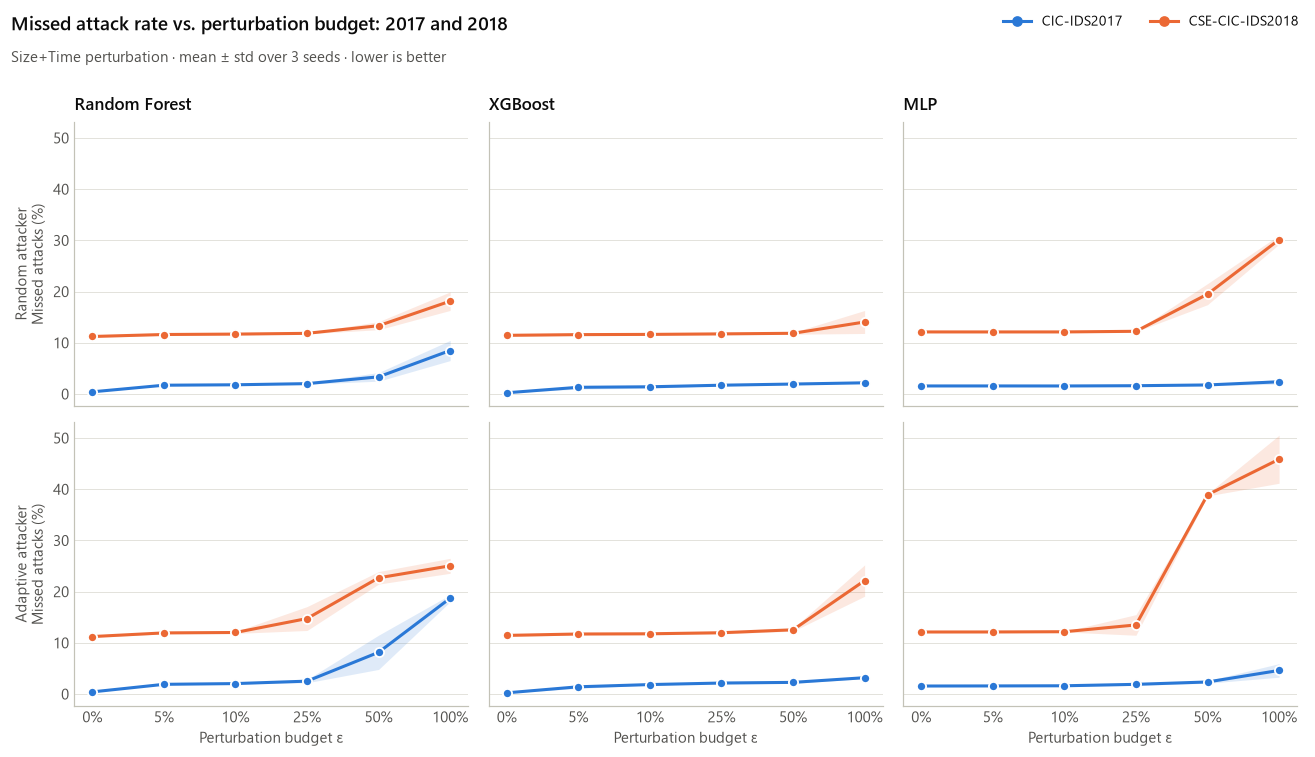

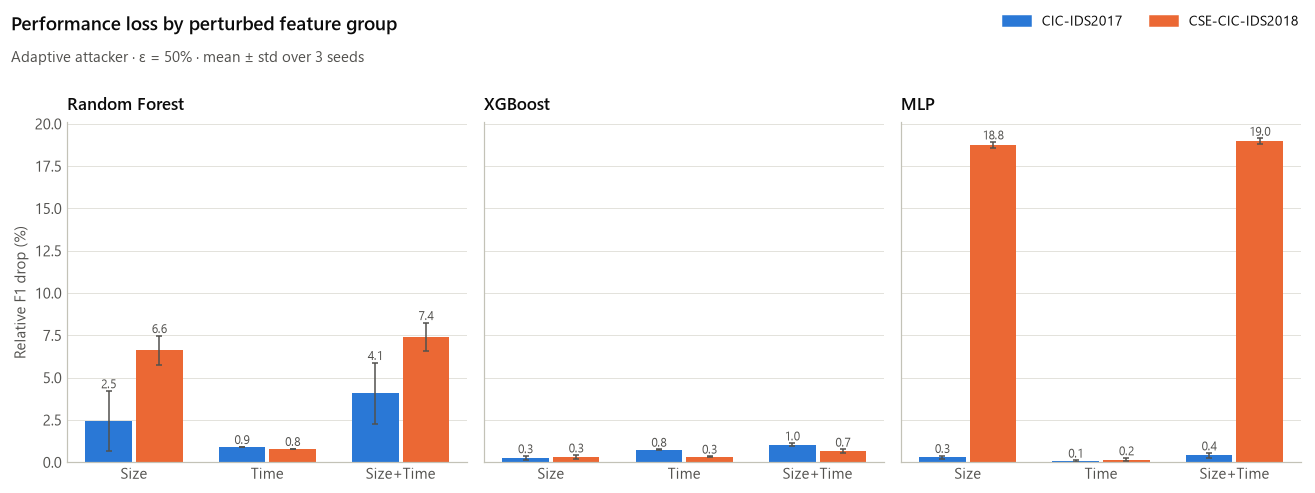

In [12]:
# Grafik K1: ε arttıkça kaçırılan saldırı oranı (Boyut+Zaman), iki veri seti üst üste
curve = (pert_all[pert_all["Group"] == "Size+Time"]
         .groupby(["Attacker", "Model", "Dataset", "Epsilon"])["Missed attacks (%)"].agg(["mean", "std"]))
x = np.arange(len(EPSILONS))
fig, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(12, 6.2), sharex=True, sharey=True)
for r, attacker in enumerate(ATTACKERS):
    for c, name in enumerate(MODEL_NAMES):
        ax = axes[r, c]
        for ds in DATASETS:
            d = curve.loc[(attacker, name, ds)]
            mean, std = d["mean"].to_numpy(), d["std"].fillna(0).to_numpy()
            ax.fill_between(x, np.maximum(mean - std, 0), mean + std, color=DATASET_COLORS[ds], alpha=0.15, linewidth=0)
            ax.plot(x, mean, color=DATASET_COLORS[ds], marker="o", markeredgecolor="white", markeredgewidth=1.2)
        ax.set_xticks(x, [f"{e * 100:.0f}%" for e in EPSILONS])
        if r == 0:
            ax.set_title(name)
        if c == 0:
            ax.set_ylabel(f"{attacker} attacker\nMissed attacks (%)")
        if r == 1:
            ax.set_xlabel("Perturbation budget ε")
fig.tight_layout()
top_legend(fig, [Line2D([], [], color=DATASET_COLORS[ds], marker="o", label=ds) for ds in DATASETS])
fig_title(fig, "Missed attack rate vs. perturbation budget: 2017 and 2018",
          f"Size+Time perturbation · mean ± std over {len(SEEDS)} seeds · lower is better")
save_fig(fig, "K1_missed_attacks_comparison")

# Grafik K2: hangi özellik grubu daha etkili? (uyarlamalı, ε = EPS_REF)
grp = (at_ref[at_ref["Attacker"] == "Adaptive"]
       .groupby(["Model", "Group", "Dataset"])["Relative F1 drop (%)"].agg(["mean", "std"]))
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(12, 3.8), sharey=True)
xg = np.arange(len(SCENARIO_GROUPS))
w = 0.38
for ax, name in zip(axes, MODEL_NAMES):
    for k, ds in enumerate(DATASETS):
        mean = [grp.loc[(name, g_, ds), "mean"] for g_ in SCENARIO_GROUPS]
        std = [grp.loc[(name, g_, ds), "std"] for g_ in SCENARIO_GROUPS]
        pos = xg + (k - 0.5) * w
        ax.bar(pos, mean, width=w * 0.92, color=DATASET_COLORS[ds], yerr=np.nan_to_num(std),
               error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 2})
        for p, v, s in zip(pos, mean, np.nan_to_num(std)):
            ax.text(p, v + s, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=INK_2)
    ax.set_xticks(xg, SCENARIO_GROUPS)
    ax.set_title(name)
axes[0].set_ylabel("Relative F1 drop (%)")
fig.tight_layout()
top_legend(fig, [plt.Rectangle((0, 0), 1, 1, color=DATASET_COLORS[ds]) for ds in DATASETS], DATASETS)
fig_title(fig, "Performance loss by perturbed feature group",
          f"Adaptive attacker · ε = {EPS_REF * 100:.0f}% · mean ± std over {len(SEEDS)} seeds")
save_fig(fig, "K2_group_effect_comparison")

### 5.1 Farkın kaynağı: saldırı türü bazında analiz

İki veri seti arasındaki farkların hangi saldırı türlerinden geldiğini görmek için modeller seed 42 ile yeniden eğitilir. Her saldırı türü için Recall hem temiz veride hem de uyarlamalı boyut saldırısı altında (ε = `EPS_REF`) hesaplanır. Ayrıca temiz veride kaçırılan saldırıların ne kadarının Infilteration sınıfından geldiği yazdırılır.

In [13]:
# Saldırı türü bazında Recall: temiz veri ve uyarlamalı boyut saldırısı (seed 42)
X_tr, X_te, y_tr, y_te = split_data(SEEDS[0])
scaler = StandardScaler().fit(X_tr)
Xs_tr = scaler.transform(X_tr).astype(np.float32)
bounds = (X_tr.min(), X_tr.max())

is_attack = (y_te == 1).to_numpy()
X_att = X_te[is_attack]
Xs_att = scaler.transform(X_att).astype(np.float32)
attack_labels = labels.loc[X_att.index]
is_infiltration = (attack_labels == "Infilteration").to_numpy()

per_type = pd.DataFrame({"Count in test": attack_labels.value_counts()})
for name in MODEL_NAMES:
    model = make_model(name, SEEDS[0]).fit(Xs_tr, y_tr.to_numpy())

    def score_fn(X_raw, model=model):
        return model.predict_proba(scaler.transform(X_raw).astype(np.float32))[:, 1]

    detected_clean = model.predict_proba(Xs_att)[:, 1] >= DECISION_THRESHOLD
    p_size = attack_probabilities("Adaptive", "Size", EPS_REF, X_att, bounds, score_fn,
                                  np.random.default_rng(SEEDS[0]))
    detected_size = p_size >= DECISION_THRESHOLD

    per_type[f"{name} · clean"] = pd.Series(detected_clean, index=X_att.index).groupby(attack_labels).mean()
    per_type[f"{name} · size attack"] = pd.Series(detected_size, index=X_att.index).groupby(attack_labels).mean()

    missed = ~detected_clean
    print(f"{name:<14} temizde kaçırılan saldırı: {missed.sum():,} "
          f"(Infilteration payı %{missed[is_infiltration].sum() / missed.sum() * 100:.1f}) · "
          f"Recall {detected_clean.mean():.4f} → Infilteration hariç {detected_clean[~is_infiltration].mean():.4f}")
    del model

per_type = per_type[per_type["Count in test"] >= 100].sort_values("Count in test", ascending=False)
show_table(per_type.reset_index(names="Attack type"),
           f"Table K4 — Recall per attack type in 2018 (seed {SEEDS[0]}; size attack: adaptive, ε = {EPS_REF * 100:.0f}%; "
           "types with at least 100 test flows)",
           "recall_per_attack_type.csv", precision=3)

Random Forest  temizde kaçırılan saldırı: 5,800 (Infilteration payı %97.7) · Recall 0.8895 → Infilteration hariç 0.9971


XGBoost        temizde kaçırılan saldırı: 5,905 (Infilteration payı %98.5) · Recall 0.8875 → Infilteration hariç 0.9981


MLP            temizde kaçırılan saldırı: 6,323 (Infilteration payı %95.7) · Recall 0.8795 → Infilteration hariç 0.9941


Attack type,Count in test,Random Forest · clean,Random Forest · size attack,XGBoost · clean,XGBoost · size attack,MLP · clean,MLP · size attack
DDOS attack-HOIC,"15,550",0.998,0.998,1.000,1.000,1.000,1.000
DoS attacks-Hulk,"13,135",1.000,1.000,1.000,1.000,1.000,1.000
Bot,"8,503",0.992,0.992,0.994,0.994,0.975,0.039
Infilteration,"6,099",0.071,0.051,0.047,0.040,0.008,0.008
SSH-Bruteforce,"5,827",1.000,0.009,1.000,0.991,0.999,0.004
DoS attacks-GoldenEye,"2,553",1.000,1.000,1.000,0.931,1.000,0.983
DoS attacks-Slowloris,626,0.997,0.997,1.000,1.000,0.981,0.973
DDOS attack-LOIC-UDP,110,1.000,1.000,1.000,1.000,1.000,1.000


## 6. Özet

Aşağıdaki hücre iki veri seti arasındaki farkları tablolardan otomatik olarak çıkarır.

In [14]:
b = base_all.groupby(["Dataset", "Model"])["F1"].mean().unstack("Dataset")
m = main.groupby(["Dataset", "Model"])[["Relative F1 drop (%)", "Robustness score"]].mean()

print("Temiz veride F1 (2017 → 2018):")
for name in MODEL_NAMES:
    print(f"   {name:<14} {b.loc[name, DATASETS[0]]:.4f} → {b.loc[name, DATASETS[1]]:.4f}"
          f"   (fark {b.loc[name, DATASETS[1]] - b.loc[name, DATASETS[0]]:+.4f})")

print(f"\nUyarlamalı saldırı, Boyut+Zaman, ε = {EPS_REF * 100:.0f}% — göreli F1 düşüşü (2017 → 2018):")
for name in MODEL_NAMES:
    a, c = m.loc[(DATASETS[0], name), "Relative F1 drop (%)"], m.loc[(DATASETS[1], name), "Relative F1 drop (%)"]
    print(f"   {name:<14} %{a:.2f} → %{c:.2f}")

for ds in DATASETS:
    order = m.loc[ds].sort_values("Robustness score", ascending=False).index.tolist()
    print(f"\nDayanıklılık sıralaması ({ds}): " + " > ".join(order))

Temiz veride F1 (2017 → 2018):
   Random Forest  0.9971 → 0.9233   (fark -0.0738)
   XGBoost        0.9980 → 0.9369   (fark -0.0611)
   MLP            0.9870 → 0.9322   (fark -0.0548)

Uyarlamalı saldırı, Boyut+Zaman, ε = 50% — göreli F1 düşüşü (2017 → 2018):
   Random Forest  %4.07 → %7.40
   XGBoost        %1.04 → %0.66
   MLP            %0.41 → %18.97

Dayanıklılık sıralaması (CIC-IDS2017): MLP > XGBoost > Random Forest

Dayanıklılık sıralaması (CSE-CIC-IDS2018): XGBoost > Random Forest > MLP


### Yorumlar

Aşağıdaki değerler, aksi belirtilmedikçe 3 seed ortalamasıdır. Saldırı türü bazındaki değerler (Tablo K4) seed 42 içindir.

**İki veri seti arasında fark var mı?** Evet. Fark iki yerde ortaya çıkmaktadır ve her ikisi de modellerden çok **veri setlerinin içeriğinden** kaynaklanmaktadır.

**1. Temiz veride başarı: 2018'de daha düşük, ancak tek bir sınıf yüzünden.**
2018'de üç modelin F1 değeri 0.92–0.94 aralığındadır (2017'de 0.987–0.998). Recall her üç modelde de yaklaşık 0.88'dir, yani saldırıların yaklaşık %12'si kaçırılmaktadır (Tablo K1). Tablo K4 bu kaybın neredeyse tamamının **Infilteration** sınıfından geldiğini göstermektedir:
- Bu sınıfta Recall yalnızca %0.8–7.1 arasındadır.
- Temiz veride kaçırılan saldırıların %96–98'i bu sınıfa aittir.
- Infilteration hariç tutulduğunda Recall 0.994–0.998'e çıkar ve 2017 ile aynı düzeye gelir.

Bu durum CSE-CIC-IDS2018'in bilinen bir etiketleme sorunudur. Infilteration senaryosunda ele geçirilen iç bilgisayarın trafiği büyük ölçüde saldırı olarak etiketlenmiş, bu da kurbanın sıradan trafiğini de kapsamaktadır. Özellikleri normal trafikten farksız akışları hiçbir modelin ayırması beklenemez. Bu nedenle 2018'deki düşük baseline, modellerin yetersizliğinden çok **veri setine özgü etiket yanlılığını** göstermektedir.

**2. Dayanıklılık sıralaması veri setine göre değişmektedir.**
Uyarlamalı Boyut+Zaman saldırısında (ε = %50) sıralama 2017'de MLP > XGBoost > Random Forest iken, 2018'de **XGBoost > Random Forest > MLP** olmuştur (Tablo K2):
- XGBoost: göreli F1 düşüşü %0.66
- Random Forest: %7.40
- MLP: %18.97

2017'de en dayanıklı olan MLP, 2018'de en kırılgan modeldir. Tablo K4 bunun nedenini göstermektedir. Paket boyutları %50'ye kadar artırıldığında:
- MLP'de **Bot** saldırılarının Recall değeri 0.975'ten 0.039'a, **SSH-Bruteforce**'unki 0.999'dan 0.004'e düşmektedir.
- Random Forest'ta SSH-Bruteforce'un Recall değeri 1.000'den 0.009'a düşmektedir.
- XGBoost ise her iki türü de tanımaya devam etmektedir (0.994 ve 0.991).

Bu iki saldırı türü küçük ve çok düzenli paketlerden oluşur. Kaybın büyüklüğünü belirleyen etken, bu türlerin veri setindeki payıdır:
- 2017'de SSH-Patator ve Bot saldırıların yalnızca yaklaşık %1.4'ünü oluşturuyordu.
- 2018'de Bot ve SSH-Bruteforce saldırıların yaklaşık %27'sini oluşturmaktadır.

Aynı zayıflık 2017'de de muhtemelen vardı, ancak bu türler az olduğu için toplam sonuca yansımamıştır. Grafik K2 de bu farkı göstermektedir: 2018'de kaybın neredeyse tamamı boyut pertürbasyonundan gelmektedir. Zaman pertürbasyonunun etkisi her iki veri setinde de küçüktür.

**3. Değişmeyen sonuçlar.**
- **H1 iki veri setinde de desteklenmektedir:** 18 kombinasyonun 17'sinde ε arttıkça Recall ve F1 anlamlı biçimde düşmektedir (Tablo K3).
- **XGBoost iki veri setinde de istikrarlıdır:** temiz veride en yüksek F1'e sahiptir ve göreli kaybı her iki veri setinde de %1'in altında veya civarındadır (%1.04 ve %0.66).
- **Uyarlamalı saldırgan her iki veri setinde de rastgele saldırgandan daha etkilidir** (Grafik K1).

**Sonuç.** Bir modelin pertürbasyona karşı dayanıklılığı yalnızca modele değil, veri setindeki saldırı türlerinin bileşimine de bağlıdır. Bu nedenle tek bir veri setinde elde edilen "en dayanıklı model" sıralaması genellenemez. Bu çalışmada iki veri setinde de tutarlı biçimde dayanıklı kalan tek model XGBoost'tur. Ayrıca 2018'deki Infilteration örneği, yüksek ya da düşük başarı oranlarının modelden çok etiket kalitesini yansıtabileceğini göstermektedir.

**Sınırlılıklar.** 2018 verisinin %30'luk rastgele bir örneği kullanılmış, 20-02-2018 günü (DDoS-LOIC-HTTP) boyutu nedeniyle dahil edilmemiş, özellik önemi ve ablation analizleri 2018 için tekrarlanmamıştır.